# HW2 - Uniform Convergence and the Limits of Learning

**Statistical and Machine Learning - M2**

Ce notebook etudie experimentalement la convergence uniforme, le principe No-Free-Lunch et le role du biais inductif. Toutes les simulations utilisent des repetitions Monte-Carlo et une graine aleatoire fixe pour rendre les resultats reproductibles.

## Imports et parametres globaux

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import log

rng = np.random.default_rng(2026)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 13

def mean_and_std(values):
    return float(np.mean(values)), float(np.std(values))

# Part I - Simulating Uniform Convergence

Pour une hypothese de risque vrai $p$, le nombre d'erreurs suit une loi binomiale $E \sim Binomial(m,p)$ et $L_S=E/m$.

## 1. Le risque empirique comme variable aleatoire

In [2]:
p_values = [0.1, 0.3, 0.7]
sample_sizes = [10, 50, 200]
n_rep = 10000

fig, axes = plt.subplots(len(p_values), len(sample_sizes), figsize=(15, 10), sharex='col', sharey='row')
for row, p in enumerate(p_values):
    for col, m in enumerate(sample_sizes):
        empirical_risks = rng.binomial(m, p, size=n_rep) / m
        ax = axes[row, col]
        ax.hist(empirical_risks, bins=min(30, m + 1), density=True, alpha=0.75, color='steelblue')
        ax.axvline(p, color='crimson', linestyle='--', label=f'$L_D={p}$')
        ax.set_title(f'p={p}, m={m}')
        ax.set_xlabel('$L_S$')
        ax.set_ylabel('Densite')
        ax.legend()
        print(f'p={p:.1f}, m={m:3d}: moyenne={np.mean(empirical_risks):.4f}, ecart-type={np.std(empirical_risks):.4f}, theorie={p:.4f}')
plt.suptitle('Distribution du risque empirique', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

print('Interpretation: la moyenne est proche de p pour tous les m (estimateur sans biais).')
print('La dispersion diminue quand m augmente, car Var(L_S)=p(1-p)/m.')

p=0.1, m= 10: moyenne=0.1016, ecart-type=0.0960, theorie=0.1000
p=0.1, m= 50: moyenne=0.0996, ecart-type=0.0420, theorie=0.1000
p=0.1, m=200: moyenne=0.0997, ecart-type=0.0213, theorie=0.1000
p=0.3, m= 10: moyenne=0.2975, ecart-type=0.1439, theorie=0.3000
p=0.3, m= 50: moyenne=0.2996, ecart-type=0.0648, theorie=0.3000
p=0.3, m=200: moyenne=0.3006, ecart-type=0.0324, theorie=0.3000
p=0.7, m= 10: moyenne=0.7011, ecart-type=0.1445, theorie=0.7000
p=0.7, m= 50: moyenne=0.7005, ecart-type=0.0654, theorie=0.7000
p=0.7, m=200: moyenne=0.6997, ecart-type=0.0325, theorie=0.7000


<Figure size 1500x1000 with 9 Axes>

Interpretation: la moyenne est proche de p pour tous les m (estimateur sans biais).
La dispersion diminue quand m augmente, car Var(L_S)=p(1-p)/m.


## 2. Probabilite de deviation et borne de Hoeffding

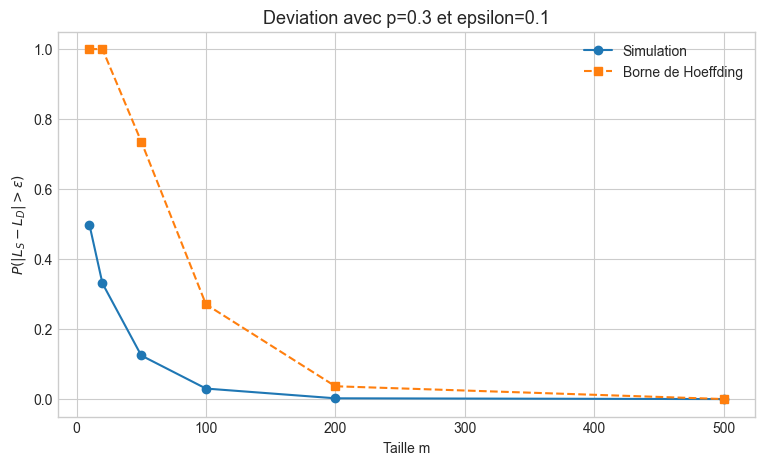

m= 10: simulation=0.4974, borne=1.0000
m= 20: simulation=0.3307, borne=1.0000
m= 50: simulation=0.1245, borne=0.7358
m=100: simulation=0.0301, borne=0.2707
m=200: simulation=0.0022, borne=0.0366
m=500: simulation=0.0000, borne=0.0001
La borne est valide mais conservative: elle controle le pire cas et n est donc pas une egalite.


In [3]:
p, epsilon = 0.3, 0.10
m_grid = np.array([10, 20, 50, 100, 200, 500])
n_rep = 30000
experimental_prob = []
hoeffding_bound = []
for m in m_grid:
    risks = rng.binomial(m, p, size=n_rep) / m
    experimental_prob.append(np.mean(np.abs(risks - p) > epsilon))
    hoeffding_bound.append(min(1.0, 2 * np.exp(-2 * m * epsilon**2)))

plt.plot(m_grid, experimental_prob, 'o-', label='Simulation')
plt.plot(m_grid, hoeffding_bound, 's--', label='Borne de Hoeffding')
plt.xlabel('Taille m'); plt.ylabel(r'$P(|L_S-L_D|>\epsilon)$')
plt.title(f'Deviation avec p={p} et epsilon={epsilon}')
plt.legend(); plt.show()

for m, prob, bound in zip(m_grid, experimental_prob, hoeffding_bound):
    print(f'm={m:3d}: simulation={prob:.4f}, borne={bound:.4f}')
print('La borne est valide mais conservative: elle controle le pire cas et n est donc pas une egalite.')

## 3. Convergence uniforme sur une classe finie

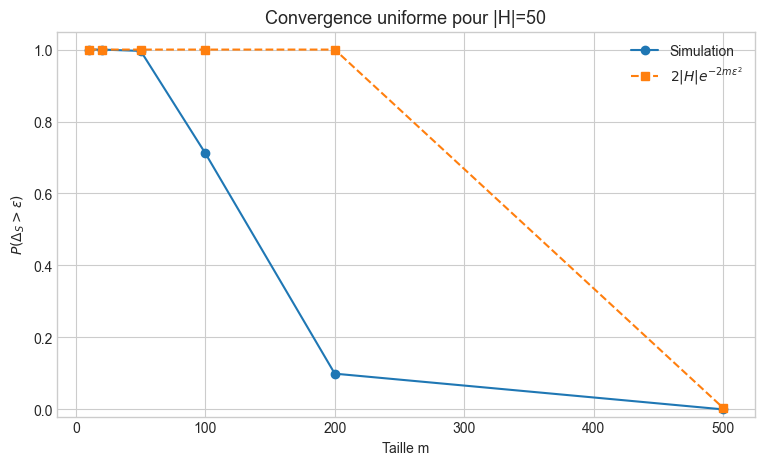

La condition uniforme doit etre satisfaite simultanement par toutes les hypotheses.
Le facteur |H| rend le controle plus exigeant que pour une seule hypothese.


In [4]:
K = 50
p_hypotheses = rng.uniform(0.05, 0.95, size=K)
epsilon = 0.10
n_rep = 20000
uniform_prob = []
uniform_bound = []
for m in m_grid:
    risks = rng.binomial(m, p_hypotheses, size=(n_rep, K)) / m
    delta = np.max(np.abs(risks - p_hypotheses), axis=1)
    uniform_prob.append(np.mean(delta > epsilon))
    uniform_bound.append(min(1.0, 2 * K * np.exp(-2 * m * epsilon**2)))

plt.plot(m_grid, uniform_prob, 'o-', label='Simulation')
plt.plot(m_grid, uniform_bound, 's--', label=r'$2|H|e^{-2m\epsilon^2}$')
plt.xlabel('Taille m'); plt.ylabel(r'$P(\Delta_S>\epsilon)$')
plt.title(f'Convergence uniforme pour |H|={K}')
plt.ylim(-0.02, 1.05); plt.legend(); plt.show()
print('La condition uniforme doit etre satisfaite simultanement par toutes les hypotheses.')
print('Le facteur |H| rend le controle plus exigeant que pour une seule hypothese.')

## 4. Effet de la taille de la classe d hypotheses

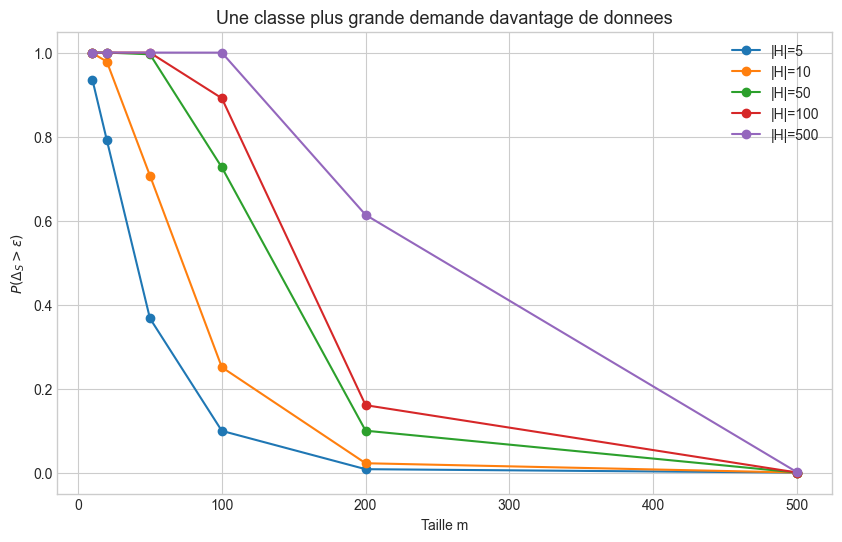

Observation: a m fixe, la probabilite de violation augmente generalement avec |H|.
La dependance theorique apparait via log(|H|) dans la taille d echantillon suffisante.


In [5]:
class_sizes = [5, 10, 50, 100, 500]
epsilon = 0.10
n_rep = 12000
plt.figure(figsize=(10, 6))
class_results = {}
for K in class_sizes:
    p_hypotheses = rng.uniform(0.05, 0.95, size=K)
    probs = []
    for m in m_grid:
        risks = rng.binomial(m, p_hypotheses, size=(n_rep, K)) / m
        delta = np.max(np.abs(risks - p_hypotheses), axis=1)
        probs.append(np.mean(delta > epsilon))
    class_results[K] = probs
    plt.plot(m_grid, probs, 'o-', label=f'|H|={K}')
plt.xlabel('Taille m'); plt.ylabel(r'$P(\Delta_S>\epsilon)$')
plt.title('Une classe plus grande demande davantage de donnees')
plt.legend(); plt.show()
print('Observation: a m fixe, la probabilite de violation augmente generalement avec |H|.')
print('La dependance theorique apparait via log(|H|) dans la taille d echantillon suffisante.')

## 5. Estimation experimentale de la sample complexity

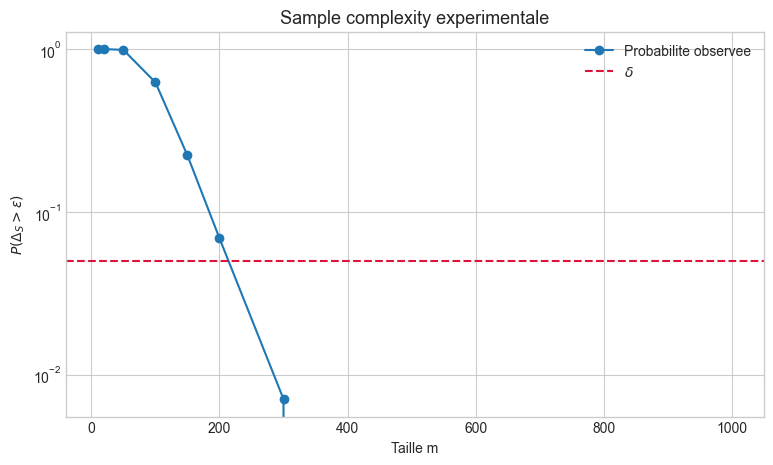

Premier m teste avec probabilite <= delta: 300
Borne theorique suffisante: m >= 380.0
La borne est une garantie suffisante issue d un pire cas; elle peut depasser le minimum empirique.


In [6]:
K, epsilon, delta = 50, 0.10, 0.05
m_candidates = np.array([10, 20, 50, 100, 150, 200, 300, 500, 750, 1000])
p_hypotheses = rng.uniform(0.05, 0.95, size=K)
n_rep = 15000
probs = []
for m in m_candidates:
    risks = rng.binomial(m, p_hypotheses, size=(n_rep, K)) / m
    delta_s = np.max(np.abs(risks - p_hypotheses), axis=1)
    probs.append(np.mean(delta_s > epsilon))
theoretical_m = log(2 * K / delta) / (2 * epsilon**2)
empirical_m = next((m for m, prob in zip(m_candidates, probs) if prob <= delta), None)
plt.semilogy(m_candidates, probs, 'o-', label='Probabilite observee')
plt.axhline(delta, color='crimson', linestyle='--', label=r'$\delta$')
plt.xlabel('Taille m'); plt.ylabel(r'$P(\Delta_S>\epsilon)$')
plt.title('Sample complexity experimentale')
plt.legend(); plt.show()
print(f'Premier m teste avec probabilite <= delta: {empirical_m}')
print(f'Borne theorique suffisante: m >= {theoretical_m:.1f}')
print('La borne est une garantie suffisante issue d un pire cas; elle peut depasser le minimum empirique.')

# Part II - Simulating No-Free-Lunch

On considere un domaine fini de taille $N$. La cible est un etiquetage totalement aleatoire: les labels non observes ne contiennent donc aucune information exploitable.

## 6. Points vus et points non vus

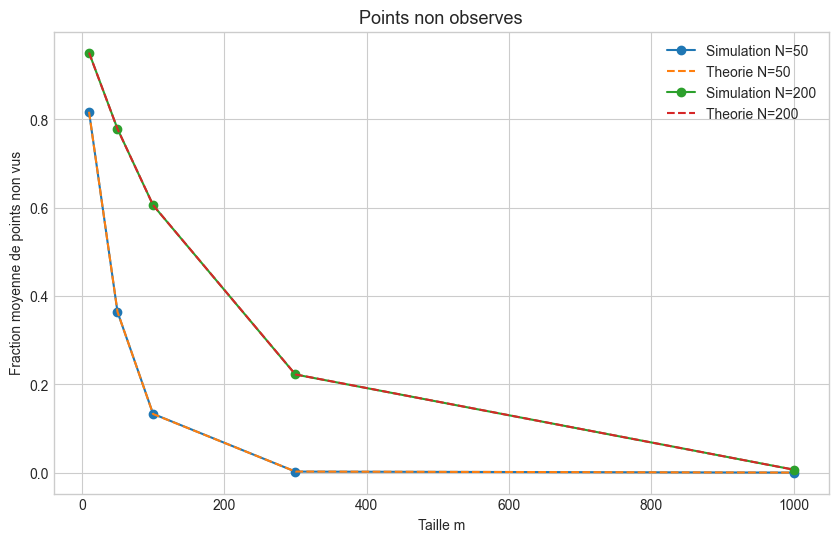

Par linearite de l esperance, la fraction moyenne est egale a la probabilite qu un point fixe soit non observe.


In [7]:
def unseen_fraction(N, m, repetitions=10000):
    samples = rng.integers(0, N, size=(repetitions, m))
    counts = np.zeros((repetitions, N), dtype=bool)
    rows = np.arange(repetitions)[:, None]
    counts[rows, samples] = True
    return np.mean(~counts, axis=1)

N_values = [50, 200]
m_values = [10, 50, 100, 300, 1000]
plt.figure(figsize=(10, 6))
for N in N_values:
    observed = []
    theory = []
    for m in m_values:
        observed.append(np.mean(unseen_fraction(N, m)))
        theory.append((1 - 1 / N) ** m)
    plt.plot(m_values, observed, 'o-', label=f'Simulation N={N}')
    plt.plot(m_values, theory, '--', label=f'Theorie N={N}')
plt.xlabel('Taille m'); plt.ylabel('Fraction moyenne de points non vus')
plt.title('Points non observes')
plt.legend(); plt.show()
print('Par linearite de l esperance, la fraction moyenne est egale a la probabilite qu un point fixe soit non observe.')

## 7. Risque sur les points non vus

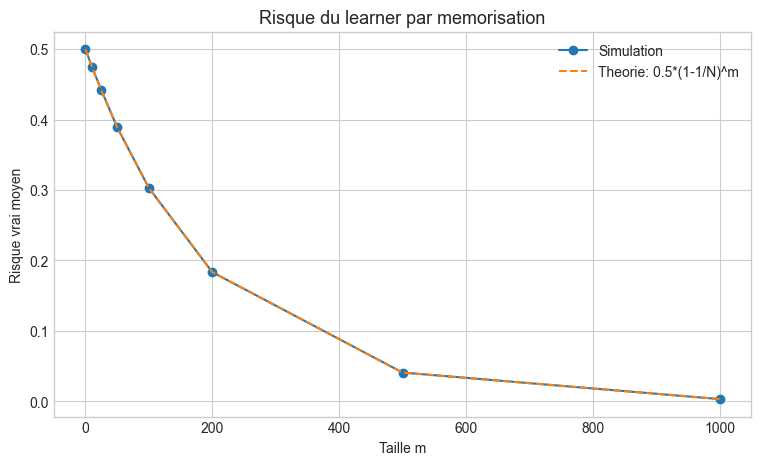

Le risque est nul sur les points vus, mais vaut en moyenne 1/2 sur les points non vus.


In [10]:
def random_target_risk(N, m, repetitions=10000, unseen_rule='zero'):
    risks = np.empty(repetitions)
    for r in range(repetitions):
        target = rng.integers(0, 2, size=N)
        sample = rng.integers(0, N, size=m)
        prediction = np.zeros(N, dtype=int)
        observed = np.zeros(N, dtype=bool)
        observed[sample] = True
        prediction[sample] = target[sample]
        if unseen_rule == 'one':
            prediction[~observed] = 1
        elif unseen_rule == 'random':
            prediction[~observed] = rng.integers(0, 2, size=np.sum(~observed))
        risks[r] = np.mean(prediction != target)
    return risks

N = 200
m_grid_nfl = np.array([0, 10, 25, 50, 100, 200, 500, 1000])
observed_risk = [np.mean(random_target_risk(N, m, repetitions=6000)) for m in m_grid_nfl]
theoretical_risk = [0.5 * (1 - 1 / N) ** m for m in m_grid_nfl]
plt.plot(m_grid_nfl, observed_risk, 'o-', label='Simulation')
plt.plot(m_grid_nfl, theoretical_risk, '--', label='Theorie: 0.5*(1-1/N)^m')
plt.xlabel('Taille m'); plt.ylabel('Risque vrai moyen')
plt.title('Risque du learner par memorisation')
plt.legend(); plt.show()
print('Le risque est nul sur les points vus, mais vaut en moyenne 1/2 sur les points non vus.')

## 8. Regles de prediction sur les points non vus

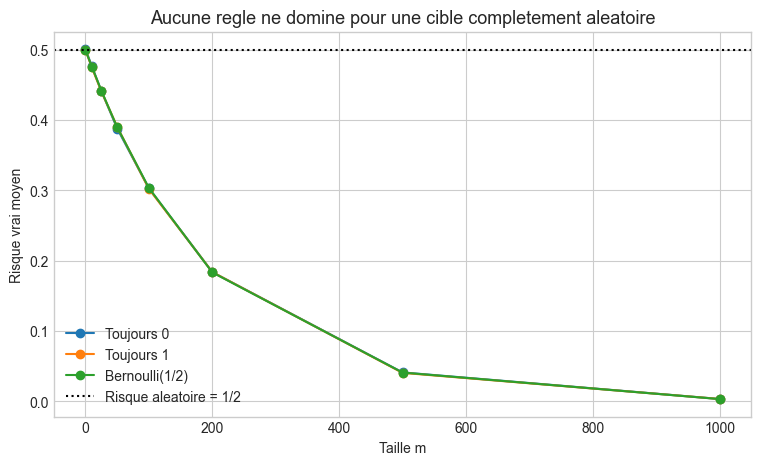

Toujours 0: risque a m=1000 = 0.0034
Toujours 1: risque a m=1000 = 0.0034
Bernoulli(1/2): risque a m=1000 = 0.0032
Les trois strategies ont le meme risque attendu sur un label inconnu: 1/2.
C est une illustration experimentale du principe No-Free-Lunch.


In [11]:
rules = ['zero', 'one', 'random']
rule_labels = {'zero': 'Toujours 0', 'one': 'Toujours 1', 'random': 'Bernoulli(1/2)'}
rule_means = {rule: [np.mean(random_target_risk(N, m, repetitions=5000, unseen_rule=rule)) for m in m_grid_nfl] for rule in rules}
for rule in rules:
    plt.plot(m_grid_nfl, rule_means[rule], 'o-', label=rule_labels[rule])
plt.axhline(0.5, color='black', linestyle=':', label='Risque aleatoire = 1/2')
plt.xlabel('Taille m'); plt.ylabel('Risque vrai moyen')
plt.title('Aucune regle ne domine pour une cible completement aleatoire')
plt.legend(); plt.show()
for rule in rules:
    print(f'{rule_labels[rule]}: risque a m=1000 = {rule_means[rule][-1]:.4f}')
print('Les trois strategies ont le meme risque attendu sur un label inconnu: 1/2.')
print('C est une illustration experimentale du principe No-Free-Lunch.')

# Part III - Introducing Prior Knowledge

La cible devient une fonction seuil $f_\theta(x)=1[x>\theta]$. Le learner utilise la classe de seuils correspondante et selectionne un seuil par ERM.

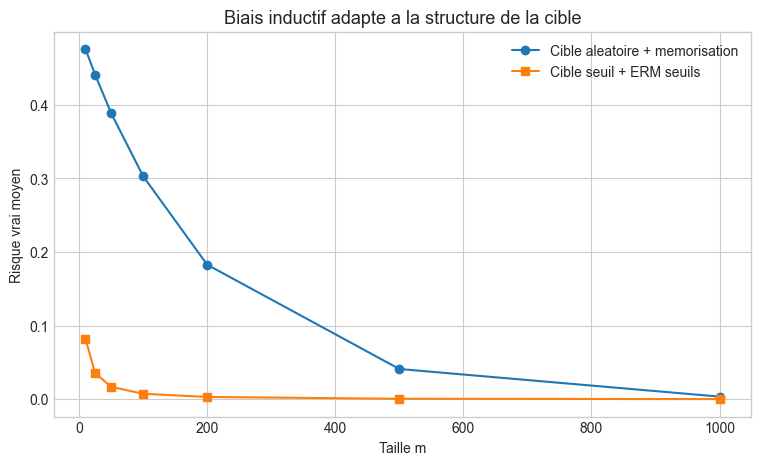

m=  10: aleatoire=0.4759, seuil=0.0818
m=  25: aleatoire=0.4412, seuil=0.0354
m=  50: aleatoire=0.3889, seuil=0.0167
m= 100: aleatoire=0.3031, seuil=0.0073
m= 200: aleatoire=0.1827, seuil=0.0029
m= 500: aleatoire=0.0409, seuil=0.0004
m=1000: aleatoire=0.0034, seuil=0.0000
La classe de seuils permet d extrapoler la relation entre les points observes, contrairement a la cible aleatoire.


In [12]:
def threshold_risk(N, m, repetitions=5000):
    risks = np.empty(repetitions)
    domain = np.arange(1, N + 1)
    thresholds = np.arange(1, N)
    for r in range(repetitions):
        theta = rng.integers(1, N)
        sample_x = rng.integers(1, N + 1, size=m)
        sample_y = (sample_x > theta).astype(int)
        hypotheses = (sample_x[None, :] > thresholds[:, None]).astype(int)
        empirical_errors = np.mean(hypotheses != sample_y[None, :], axis=1)
        best_threshold = thresholds[np.argmin(empirical_errors)]
        prediction = (domain > best_threshold).astype(int)
        target = (domain > theta).astype(int)
        risks[r] = np.mean(prediction != target)
    return risks

N = 200
threshold_risks = [np.mean(threshold_risk(N, m, repetitions=5000)) for m in m_grid_nfl[1:]]
random_risks = [np.mean(random_target_risk(N, m, repetitions=5000)) for m in m_grid_nfl[1:]]
plt.plot(m_grid_nfl[1:], random_risks, 'o-', label='Cible aleatoire + memorisation')
plt.plot(m_grid_nfl[1:], threshold_risks, 's-', label='Cible seuil + ERM seuils')
plt.xlabel('Taille m'); plt.ylabel('Risque vrai moyen')
plt.title('Biais inductif adapte a la structure de la cible')
plt.legend(); plt.show()
for m, random_risk, threshold_risk_value in zip(m_grid_nfl[1:], random_risks, threshold_risks):
    print(f'm={m:4d}: aleatoire={random_risk:.4f}, seuil={threshold_risk_value:.4f}')
print('La classe de seuils permet d extrapoler la relation entre les points observes, contrairement a la cible aleatoire.')

## 10-11. Analyse finale

Les simulations montrent que $L_S(h)$ se concentre autour de $L_D(h)$ lorsque $m$ augmente, avec une variance qui decroit en $1/m$. La convergence uniforme ajoute une contrainte simultanee sur toutes les hypotheses; une classe plus grande augmente donc la probabilite qu au moins une hypothese ait une deviation importante. Les bornes de Hoeffding et de classe finie sont des garanties de pire cas: elles sont utiles pour certifier un niveau de confiance, mais souvent conservatives par rapport au minimum observe experimentalement.

Dans l experience No-Free-Lunch, les labels des points non vus sont independants des labels observes. Aucun choix de prediction sur ces points ne peut donc battre systematiquement les autres: le risque attendu reste $1/2$ sur la partie non observee. Enfin, lorsque les cibles appartiennent a la famille des seuils et que le learner utilise la meme famille, l hypothese structurelle fournit un biais inductif pertinent. ERM peut alors generaliser a des points absents de l echantillon en exploitant la position du seuil, ce qui explique la baisse rapide du risque.

**Conclusion.** La generalisation ne vient pas seulement de la quantite de donnees: elle depend aussi de la capacite de la classe d hypotheses et de l adequation entre le biais inductif et la structure reelle des cibles.